In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import lightkurve as lk

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.config import PROCESSED_DIR, PROCESSED_FILE

tce_data = pd.read_csv(PROCESSED_DIR / PROCESSED_FILE)

/Users/quinnreilly/Documents/NEU-2026-27/CS4100_AI/exoplanet/.venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Raw Lightcurve Data
SearchResult containing 17 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 01 2009 Kepler    1800 kplr000757450      0.0
  1 Kepler Quarter 02 2009 Kepler    1800 kplr000757450      0.0
  2 Kepler Quarter 03 2009 Kepler    1800 kplr000757450      0.0
  3 Kepler Quarter 04 2010 Kepler    1800 kplr000757450      0.0
  4 Kepler Quarter 05 2010 Kepler    1800 kplr000757450      0.0
  5 Kepler Quarter 06 2010 Kepler    1800 kplr000757450      0.0
  6 Kepler Quarter 07 2010 Kepler    1800 kplr000757450      0.0
  7 Kepler Quarter 08 2011 Kepler    1800 kplr000757450      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr000757450      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr000757450      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr000757450      0.0
 11 Kepler Quarter 12 2012 

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

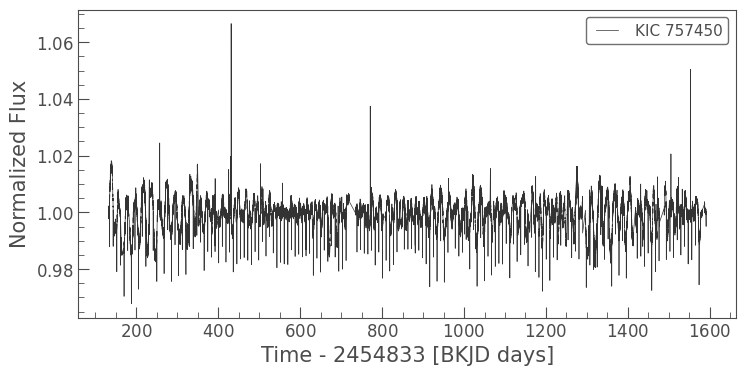

In [28]:
print("Raw Lightcurve Data")
search = lk.search_lightcurve(target= "KIC 757450", mission="Kepler", cadence="long")
print(search)
lightcurve = search.download_all().stitch().remove_nans()
lightcurve.plot()


In [34]:
#download, flatten and fold a tce
def fold_tce(row):
    # create one long lightcurve
    search = lk.search_lightcurve(f"KIC {row.kepid}", mission="Kepler", cadence="long")
    lightcurve = search.download_all().stitch().remove_nans()

    period = row.tce_period
    t0 = row.tce_time0bk
    duration_days = row.tce_duration / 24

    #build TF array for each measurement, T if a measurement falls inside a dip
    mask = lightcurve.create_transit_mask(period= period, duration=duration_days * 1.5, transit_time=t0)

    # removes the low frequency trend, ignoring dips denoted in the mask
    flattened = lightcurve.flatten(mask=mask)

    #cut up and overlay all one-period pieces so overall pattern is clearer
    return flattened.fold(period=period, epoch_time= t0), duration_days

kepid               757450
tce_plnt_num             1
tce_period         8.88492
tce_time0bk        134.452
tce_duration         2.078
av_training_set         PC
label                    1
Name: 2, dtype: object


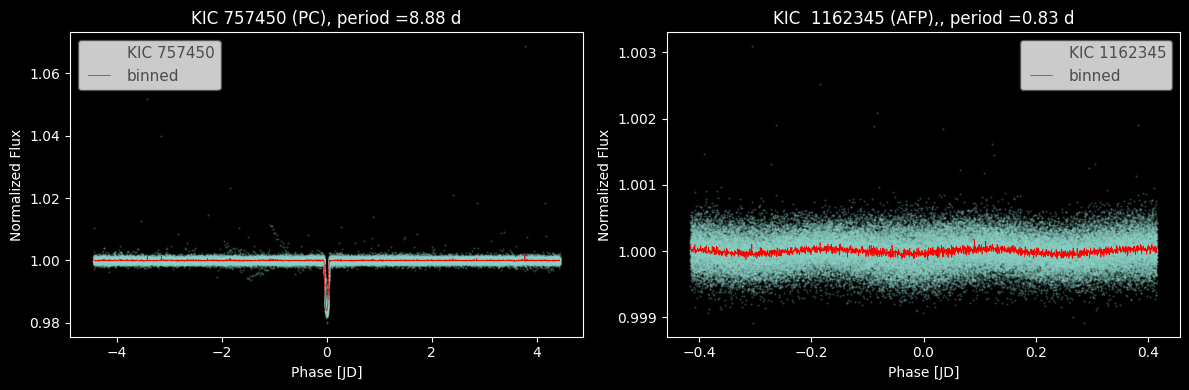

In [35]:
# KIC 757450 is PC w/ 8.9 day period
# KIC 1162345 is AFP w/ 0.83 day period

real_planet = tce_data[(tce_data.kepid == 757450) & (tce_data.tce_plnt_num == 1)].iloc[0]
fake_planet = tce_data[(tce_data.kepid == 1162345) & (tce_data.tce_plnt_num == 2)].iloc[0]

print(real_planet)

#plot
fig, axes = plt.subplots(1,2, figsize=(12, 4))

#real
folded, duration = fold_tce(real_planet)
folded.scatter(ax= axes[0], s=1,  alpha=0.3)
folded.bin(bins = 2001).plot( ax=axes[0], color='red', label = 'binned')
axes[0].set_title(f"KIC 757450 (PC), period ={real_planet.tce_period:.2f} d")

#fake
folded, duration = fold_tce(fake_planet )
folded.scatter(ax= axes[1], s=1,  alpha=0.3)
folded.bin(bins = 2001).plot( ax=axes[1], color='red', label='binned')
axes[1].set_title(f"KIC  1162345 (AFP),, period ={fake_planet.tce_period:.2f} d")

plt.tight_layout()
plt.show()
